# GFTM $B_\parallel$ extent at large WIDTH (Fusion_PhD-38e9.30)

GFTM's third field is $\sigma = \delta B_\parallel/(B_\mathrm{unit}\,k_\perp\rho_\mathrm{unit})$; pyro PR #613 converts it pointwise,
$\delta B_\parallel/B_\mathrm{unit} = k_\perp\rho_\mathrm{unit}\,\sigma(\theta)$. Question: why does the converted $B_\parallel$ extent go wrong at large WIDTH?

Tests, all against the GS2-KBM population of SPR-045 / M1 `kbm_8d`:
1. extent of GFTM's **raw** $\sigma$ against GS2's $\delta B_\parallel/k_\perp$, and of the **converted** $B_\parallel$ against GS2's $\delta B_\parallel$, vs WIDTH;
2. **synthetic**: GS2's own $\sigma_\mathrm{GS2}=\delta B_\parallel/k_\perp$ projected onto GFTM's basis (GFTM's quadrature), multiplied back by $k_\perp$. If this alone reproduces the error, the cause is representing $\sigma$ in the basis, not GFTM's physics;
3. the same synthetic test with a Galerkin-consistent reconstruction $P_N[k_\perp P_N\sigma]$ (what GFTM's operator sees), to ask whether any reader could recover $\delta B_\parallel$;
4. eigenfunctions $|B_\parallel(\theta)|$ and $|\sigma(\theta)|$, GFTM vs GS2, at small and large WIDTH.

In [1]:
from pathlib import Path
import os
import warnings
from multiprocessing import get_context
from dotenv import load_dotenv
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from numpy.polynomial.hermite import hermgauss
import pyrokinetics
from pyrokinetics import Pyro, PyroHypercube
from pyrokinetics.pyroscan import PyroScanGKOutput
from pyrokinetics.diagnostics.extent import Extent
from pyrokinetics.local_geometry.metric import MetricTerms
from matplotlib.ticker import StrMethodFormatter
from general_analysis import mode_classification as mc

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir())
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
load_dotenv(ROOT / "local.env", override=True)
print("pyrokinetics", pyrokinetics.__file__)
warnings.filterwarnings("ignore")

analysis_name = "gftm_bpar_extent"
data_root = Path(os.environ["GK_DATA_ROOT"]).expanduser()
project = "LATIN_HYPERCUBE"
cases = ["SPR-045", "M1"]
fraction = 0.95
gftm_dir = lambda db: data_root / "GFTM" / "Runs" / project / db / "kbm_8d"
bpar_root = data_root / "GFTM" / "Runs" / "bpar_fig6_rebuild"   # same runs re-saved with the pyro PR #613 reader (Fusion_PhD-38e9.29)
wtag = lambda w: f"w{w:.4f}".replace(".", "p")
fs_title, fs_legend = 16, 12
field_labels = {"phi": r"$\phi$", "bpar": r"$B_\parallel$"}


def log_xticks(ax, ticks=(0.2, 0.4, 0.7, 1, 2, 4)):
    ax.set_xticks(ticks)
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    ax.minorticks_off()


def mag(v):
    return np.asarray(getattr(v.data, "magnitude", v.data))


def extent(theta, power):
    return float(Extent._compute(xr.DataArray(power, dims="theta", coords={"theta": theta}), fraction)[0])


# GFTM's basis and quadrature (as gftm_quadrature_extent.ipynb Part A): theta = WIDTH x, nx = 2 NXGRID - 1 Gauss-Hermite nodes
def basis(nbasis, x):
    h = np.zeros((nbasis, len(x)))
    h[0] = np.pi ** -0.25 * np.exp(-x ** 2 / 2)
    if nbasis > 1:
        h[1] = np.sqrt(2) * x * h[0]
    for j in range(2, nbasis):
        h[j] = np.sqrt(2 / j) * x * h[j - 1] - np.sqrt((j - 1) / j) * h[j - 2]
    return h


def coefficients(theta_src, f_src, width, nbasis, nxgrid):
    x, w = hermgauss(2 * nxgrid - 1)
    f_nodes = np.interp(width * x, theta_src, f_src.real, left=0, right=0) + 1j * np.interp(width * x, theta_src, f_src.imag, left=0, right=0)
    return basis(nbasis, x) @ (w * np.exp(x ** 2) * f_nodes)


def b0_solve(theta_src, sigma_src, k_perp_of_theta, width, nbasis, nxgrid):
    # coefficients of sigma from Mat(k_perp^2) c = <psi, k_perp^2 sigma>: the FIELD_GALERKIN=T form Mat(b0)^-1 Mat(J1) (b0x ~ (k_perp/ky)^2),
    # which minimises int (k_perp/ky)^2 |sigma - sigma_true|^2, i.e. the L2 error of dB_par itself
    x, w = hermgauss(2 * nxgrid - 1)
    h = basis(nbasis, x)
    k2 = k_perp_of_theta(width * x) ** 2
    sigma_nodes = np.interp(width * x, theta_src, sigma_src.real, left=0, right=0) + 1j * np.interp(width * x, theta_src, sigma_src.imag, left=0, right=0)
    return np.linalg.solve((h * (w * np.exp(x ** 2) * k2)) @ h.T, h @ (w * np.exp(x ** 2) * k2 * sigma_nodes))


def k_perp_galerkin(coeffs, k_perp_of_theta, width, nbasis, nxgrid):
    # coefficients of P_N[k_perp * sum_j c_j psi_j], GFTM's quadrature
    x, w = hermgauss(2 * nxgrid - 1)
    h = basis(nbasis, x)
    return (h * (w * np.exp(x ** 2) * k_perp_of_theta(width * x))) @ h.T @ coeffs

pyrokinetics /pitagora_work/FUPB2_QLTURB/fwatts/pyro_bpar_38e927/src/pyrokinetics/__init__.py


## GS2 reference: KBM population, eigenfunctions, and $k_\perp(\theta)$ per sample
Population as `gftm_quadrature_extent.ipynb` (user classifier on per-run GS2 loads, pending Fusion_PhD-k8w8).
$k_\perp/k_y$ comes from pyro's `MetricTerms` on each sample's geometry (the GFTM scan's `sample_pyro`, GFTM's $B_\mathrm{unit}$ units, as the #613 reader uses).
Only the shape of $k_\perp(\theta)$ matters for an extent.

In [2]:
def gs2_label(args):   # TEMPORARY per-run load, until Fusion_PhD-k8w8
    db, name = args
    try:
        pyro = Pyro(gk_file=data_root / "GS2" / "Runs" / project / db / "kbm_8d" / name / "gs2.in")
        pyro.load_gk_output(load_fields=True, load_fluxes=True)
        return mc.classify(mc.indicators(pyro))
    except Exception:
        return "load_failed"


theta_metric = {}
gs2 = {}
for db in cases:
    gs2_last = PyroScanGKOutput.from_netcdf(data_root / "GS2" / "Runs" / project / db / "kbm_8d" / "pyro_cube" / "cube.nc").data
    gs2_avg = PyroScanGKOutput.from_netcdf(data_root / "GS2" / "Runs" / project / db / "kbm_8d" / "pyro_cube_avg" / "cube.nc").data
    names = gs2_avg.sample_name.values.astype(str)
    assert (gs2_last.sample_name.values.astype(str) == names).all()
    with get_context("fork").Pool(int(os.environ.get("SLURM_CPUS_PER_TASK", 4))) as pool:
        label = np.array(pool.map(gs2_label, [(db, n) for n in names], chunksize=4))
    gamma_gs2 = mag(gs2_avg.growth_rate)
    eigenfunctions = gs2_last.eigenfunctions.transpose("sample", "field", "theta")
    bpar_gs2, phi_gs2 = mag(eigenfunctions.sel(field="bpar")), mag(eigenfunctions.sel(field="phi"))
    kbm = (label == "KBM") & (gamma_gs2 > 0) & np.isfinite(bpar_gs2).all(1) & np.isfinite(phi_gs2).all(1)

    gftm_scan = PyroHypercube(pyroscan_json=gftm_dir(db) / "qx_f05_w1p0000_nb59_nx65" / "pyroscan.json", load_base_pyro=True)
    k_perp_curves = []
    for name in names:
        theta_long, k_perp_long = MetricTerms(gftm_scan.sample_pyro(name).local_geometry, ntheta=256).k_perp(ky=1.0, theta0=0.0, nperiod=6)
        k_perp_curves.append(np.asarray(getattr(k_perp_long, "m", k_perp_long)))
    theta_metric[db] = np.asarray(getattr(theta_long, "m", theta_long))
    theta_gs2 = mag(gs2_last.theta)
    k_perp_gs2 = np.array([np.interp(theta_gs2, theta_metric[db], k) for k in k_perp_curves])
    gs2[db] = dict(names=names, kbm=kbm, theta=theta_gs2, phi=phi_gs2, bpar=bpar_gs2, k_perp_curves=np.array(k_perp_curves),
                   sigma=bpar_gs2 / k_perp_gs2)
    gs2[db]["ext"] = {f: np.array([extent(theta_gs2, np.abs(e) ** 2) if ok else np.nan for e, ok in zip(gs2[db][f], kbm)]) for f in ("phi", "bpar", "sigma")}
    k_ratio = np.array([np.interp([0, np.pi], theta_metric[db], k) for k in k_perp_curves])[kbm]
    print(db, "GS2-KBM n =", kbm.sum(), "| median extent phi / B_par / B_par/k_perp:", *[round(float(np.nanmedian(gs2[db]["ext"][f])), 2) for f in ("phi", "bpar", "sigma")],
          "| median k_perp/ky at theta 0 and pi:", np.median(k_ratio, 0).round(2))

/pitagora_work/FUPB2_QLTURB/fwatts/pyro_bpar_38e927/src/pyrokinetics/gk_code/gk_output.py:694: UserWarning: Mode frequency may not be accurate due to low temporal resolution
  warnings.warn(


/pitagora_work/FUPB2_QLTURB/fwatts/General_Analysis_38e924/.venv/lib/python3.14/site-packages/xarray/core/variable.py:363: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  data = np.asarray(data)


/pitagora_work/FUPB2_QLTURB/fwatts/General_Analysis_38e924/.venv/lib/python3.14/site-packages/xarray/core/variable.py:363: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  data = np.asarray(data)


/pitagora_work/FUPB2_QLTURB/fwatts/General_Analysis_38e924/.venv/lib/python3.14/site-packages/xarray/core/variable.py:363: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  data = np.asarray(data)


/pitagora_work/FUPB2_QLTURB/fwatts/General_Analysis_38e924/.venv/lib/python3.14/site-packages/xarray/core/variable.py:363: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  data = np.asarray(data)


...

/pitagora_work/FUPB2_QLTURB/fwatts/General_Analysis_38e924/.venv/lib/python3.14/site-packages/xarray/core/variable.py:363: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  data = np.asarray(data)


/pitagora_work/FUPB2_QLTURB/fwatts/General_Analysis_38e924/.venv/lib/python3.14/site-packages/xarray/core/variable.py:363: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  data = np.asarray(data)


/pitagora_work/FUPB2_QLTURB/fwatts/pyro_bpar_38e927/src/pyrokinetics/gk_code/gk_output.py:694: UserWarning: Mode frequency may not be accurate due to low temporal resolution
  warnings.warn(


/pitagora_work/FUPB2_QLTURB/fwatts/General_Analysis_38e924/.venv/lib/python3.14/site-packages/xarray/core/variable.py:363: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  data = np.asarray(data)


M1 GS2-KBM n = 161 | median extent phi / B_par / B_par/k_perp: 2.66 2.1 1.49 | median k_perp/ky at theta 0 and pi: [0.22 6.15]


## GFTM: raw $\sigma$ (original objects, pre-#613) vs converted $B_\parallel$ (#613 re-saves), dominant mode, NBASIS 59 / NXGRID 65, every WIDTH
The original `pyroscan.nc` of each leaf holds $\sigma$ as `bpar` (the reader before #613); `bpar_fig6_rebuild` holds $k_\perp\rho_\mathrm{unit}\,\sigma$.

In [3]:
def gftm_dominant(db, path):
    output = PyroScanGKOutput.from_netcdf(path).data
    idx = list(output.sample_name.values.astype(str))
    idx = np.array([idx.index(n) for n in gs2[db]["names"]])
    gamma = mag(output.growth_rate.transpose("sample", "mode"))[idx]
    dominant = np.argmax(np.where(gamma > 0, gamma, -np.inf), 1)       # dominant mode = argmax growth
    unstable = gamma.max(1) > 0
    fields = mag(output.eigenfunctions.transpose("sample", "mode", "field", "theta"))[idx, dominant]
    return mag(output.theta), {f: np.where(unstable[:, None], fields[:, i], np.nan) for i, f in enumerate(output.field.values)}


def log_ratio(theta, field, reference):
    gftm_extent = np.array([extent(theta, np.abs(e) ** 2) if np.isfinite(e).all() else np.nan for e in field])
    return np.log10(gftm_extent / reference)


widths_nb59 = sorted(float(p.name.split("_")[2][1:].replace("p", ".")) for p in gftm_dir("SPR-045").glob("qx_f05_w*_nb59_nx65"))
error = {}      # (db, quantity) -> median |log10 extent ratio| per WIDTH
for db in cases:
    k = gs2[db]["kbm"]
    for quantity in ("phi", "sigma_raw", "bpar_converted"):
        error[db, quantity] = []
    for width in widths_nb59:
        leaf = f"qx_f05_{wtag(width)}_nb59_nx65"
        theta_gftm, fields_raw = gftm_dominant(db, gftm_dir(db) / leaf / "pyroscan.nc")
        _, fields_converted = gftm_dominant(db, bpar_root / db / leaf / "pyroscan.nc")
        error[db, "phi"].append(np.nanmedian(np.abs(log_ratio(theta_gftm, fields_converted["phi"][k], gs2[db]["ext"]["phi"][k]))))
        error[db, "sigma_raw"].append(np.nanmedian(np.abs(log_ratio(theta_gftm, fields_raw["bpar"][k], gs2[db]["ext"]["sigma"][k]))))
        error[db, "bpar_converted"].append(np.nanmedian(np.abs(log_ratio(theta_gftm, fields_converted["bpar"][k], gs2[db]["ext"]["bpar"][k]))))
theta_out = theta_gftm
print("GFTM output theta:", len(theta_out), "points, max", theta_out.max().round(2))

GFTM output theta: 289 points, max 28.27


## Synthetic: GS2's $\sigma$ through GFTM's basis
$B^{\rm pw} = k_\perp\,P_N[\sigma_\mathrm{GS2}]$ (pointwise, as the #613 reader) and $B^{\rm G} = P_N[k_\perp P_N[\sigma_\mathrm{GS2}]]$ (Galerkin-consistent reconstruction), both against GS2's $\delta B_\parallel$.
$P_N[\cdot]$ with GFTM's quadrature is what production GFTM does for $\sigma$: its coefficients are $\langle\psi_i, (J_1/b_{0x})\,n\rangle$ (pointwise quasi-inverse, `gftm_matrix.f90`).
$B^{\rm S} = k_\perp\,S_N[\sigma_\mathrm{GS2}]$ instead solves $\mathrm{Mat}(k_\perp^2)\,c = \langle\psi, k_\perp^2\sigma\rangle$, the form of `FIELD_GALERKIN=T` ($\mathrm{Mat}(b_0)^{-1}\mathrm{Mat}(J_1)$, Fusion_PhD-qp5.24).
Control: $P_N[\delta B_{\parallel,\mathrm{GS2}}]$, projecting $B_\parallel$ itself.

In [4]:
sections = {11: 17, 27: 33, 43: 49, 59: 65}
widths_synthetic = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0, 1.2, 1.5, 2.0, 3.0, 4.0]
synthetic = {}  # (db, nbasis, kind) -> median |log10 extent ratio| per WIDTH
for db in cases:
    ref = gs2[db]
    samples = np.flatnonzero(ref["kbm"])
    for nbasis, nxgrid in sections.items():
        rows = {kind: [] for kind in ("projected_bpar", "pointwise", "galerkin", "b0_solve")}
        for width in widths_synthetic:
            per_sample = []
            for i in samples:
                k_perp_out = np.interp(theta_out, theta_metric[db], ref["k_perp_curves"][i])
                sigma_coeffs = coefficients(ref["theta"], ref["sigma"][i], width, nbasis, nxgrid)
                bpar_coeffs = coefficients(ref["theta"], ref["bpar"][i], width, nbasis, nxgrid)
                k_perp_of_theta = lambda t: np.interp(t, theta_metric[db], ref["k_perp_curves"][i])
                galerkin_coeffs = k_perp_galerkin(sigma_coeffs, k_perp_of_theta, width, nbasis, nxgrid)
                solve_coeffs = b0_solve(ref["theta"], ref["sigma"][i], k_perp_of_theta, width, nbasis, nxgrid)
                h_out = basis(nbasis, theta_out / width)
                per_sample.append([extent(theta_out, np.abs(c @ h_out * scale) ** 2) / ref["ext"]["bpar"][i]
                                   for c, scale in ((bpar_coeffs, 1), (sigma_coeffs, k_perp_out), (galerkin_coeffs, 1), (solve_coeffs, k_perp_out))])
            for kind, values in zip(rows, np.median(np.abs(np.log10(per_sample)), 0)):
                rows[kind].append(values)
        for kind in rows:
            synthetic[db, nbasis, kind] = rows[kind]
    print(db, "synthetic NBASIS 59 pointwise:", dict(zip(widths_synthetic, np.round(synthetic[db, 59, "pointwise"], 2))))

SPR-045 synthetic NBASIS 59 pointwise: {0.3: np.float64(0.01), 0.4: np.float64(0.02), 0.5: np.float64(0.03), 0.6: np.float64(0.12), 0.7: np.float64(0.36), 0.8: np.float64(0.63), 1.0: np.float64(0.85), 1.2: np.float64(1.05), 1.5: np.float64(1.14), 2.0: np.float64(1.27), 3.0: np.float64(1.35), 4.0: np.float64(1.35)}


M1 synthetic NBASIS 59 pointwise: {0.3: np.float64(0.01), 0.4: np.float64(0.01), 0.5: np.float64(0.01), 0.6: np.float64(0.01), 0.7: np.float64(0.01), 0.8: np.float64(0.01), 1.0: np.float64(0.02), 1.2: np.float64(0.08), 1.5: np.float64(1.03), 2.0: np.float64(1.28), 3.0: np.float64(1.38), 4.0: np.float64(1.39)}


### fig1: extent error vs WIDTH, NBASIS 59 / NXGRID 65
GFTM: $\phi$, raw $\sigma$ (vs GS2 $\delta B_\parallel/k_\perp$), converted $B_\parallel$ (vs GS2 $\delta B_\parallel$). Dashed: synthetic GS2 $\sigma$ through GFTM's basis, pointwise and Galerkin.

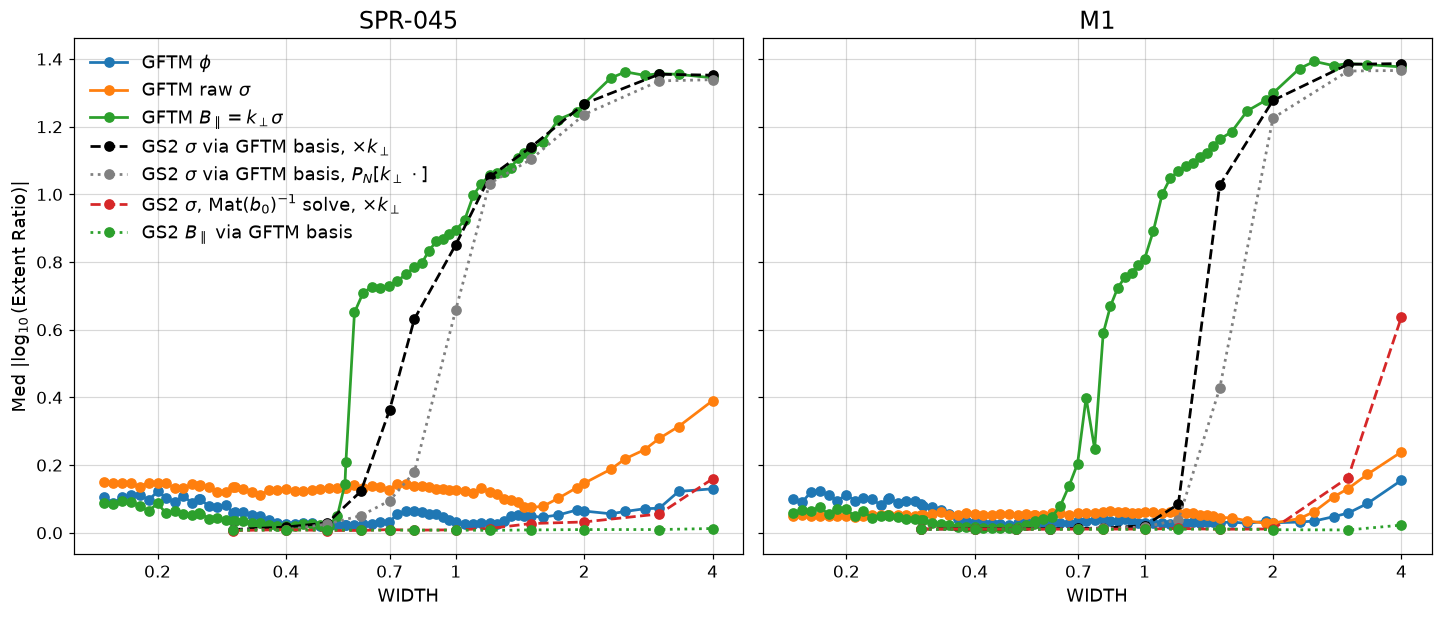

In [5]:
fig1, axes1 = plt.subplots(1, len(cases), figsize=(13, 5.5), sharey=True)
for ax, db in zip(axes1, cases):
    ax.plot(widths_nb59, error[db, "phi"], color="C0", label=r"GFTM $\phi$")
    ax.plot(widths_nb59, error[db, "sigma_raw"], color="C1", label=r"GFTM raw $\sigma$")
    ax.plot(widths_nb59, error[db, "bpar_converted"], color="C2", label=r"GFTM $B_\parallel = k_\perp\sigma$")
    ax.plot(widths_synthetic, synthetic[db, 59, "pointwise"], color="k", ls="--", label=r"GS2 $\sigma$ via GFTM basis, $\times k_\perp$")
    ax.plot(widths_synthetic, synthetic[db, 59, "galerkin"], color="grey", ls=":", label=r"GS2 $\sigma$ via GFTM basis, $P_N[k_\perp\,\cdot]$")
    ax.plot(widths_synthetic, synthetic[db, 59, "b0_solve"], color="C3", ls="--", label=r"GS2 $\sigma$, $\mathrm{Mat}(b_0)^{-1}$ solve, $\times k_\perp$")
    ax.plot(widths_synthetic, synthetic[db, 59, "projected_bpar"], color="C2", ls=":", label=r"GS2 $B_\parallel$ via GFTM basis")
    ax.set(xscale="log", xlabel="WIDTH")
    log_xticks(ax)
    ax.set_title(db, fontsize=fs_title)
axes1[0].set_ylabel(r"Med $|\log_{10}$(Extent Ratio)$|$")
axes1[0].legend(fontsize=fs_legend)
plt.show()

### fig2: synthetic error vs WIDTH per NBASIS (does it converge with NBASIS?). Solid: production pointwise $P_N$; dashed: $\mathrm{Mat}(b_0)^{-1}$ solve

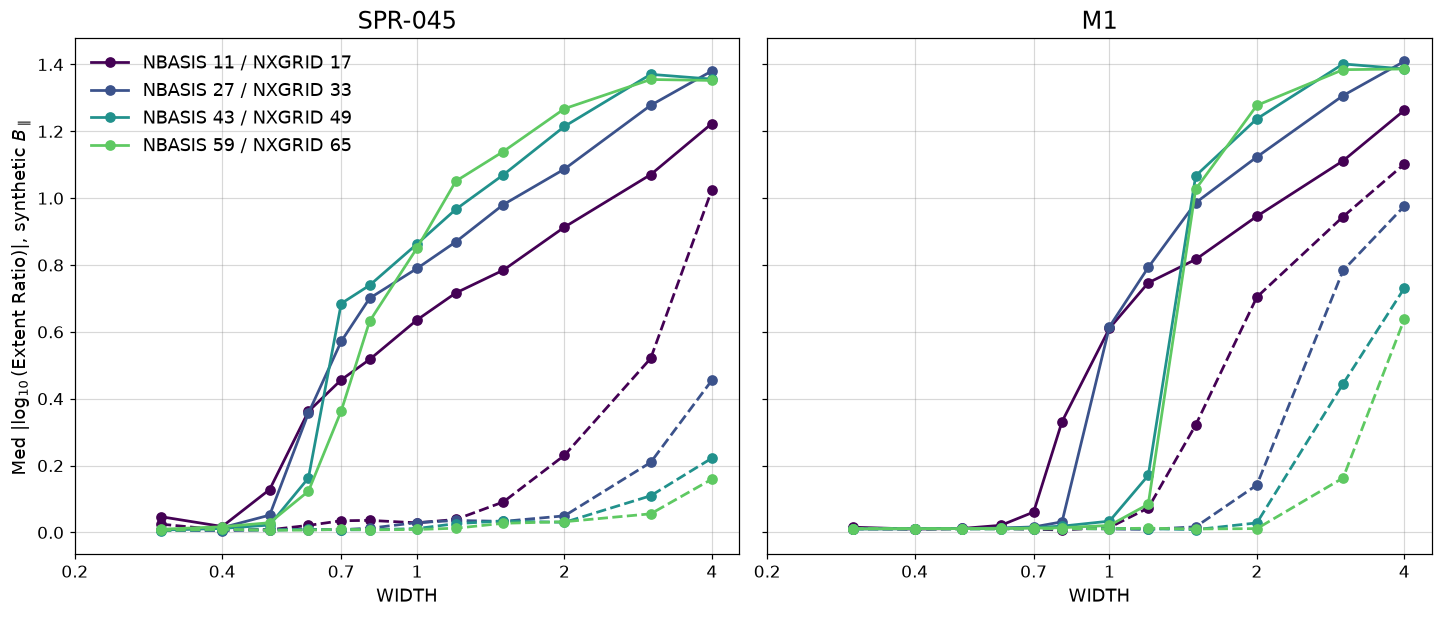

In [6]:
fig2, axes2 = plt.subplots(1, len(cases), figsize=(13, 5.5), sharey=True)
for ax, db in zip(axes2, cases):
    for j, nbasis in enumerate(sections):
        ax.plot(widths_synthetic, synthetic[db, nbasis, "pointwise"], color=plt.cm.viridis(j / len(sections)), label=f"NBASIS {nbasis} / NXGRID {sections[nbasis]}")
        ax.plot(widths_synthetic, synthetic[db, nbasis, "b0_solve"], color=plt.cm.viridis(j / len(sections)), ls="--")
    ax.set(xscale="log", xlabel="WIDTH")
    log_xticks(ax)
    ax.set_title(db, fontsize=fs_title)
axes2[0].set_ylabel(r"Med $|\log_{10}$(Extent Ratio)$|$, synthetic $B_\parallel$")
axes2[0].legend(fontsize=fs_legend)
plt.show()

### fig3: eigenfunctions, one SPR-045 and one M1 GS2-KBM sample (median GS2 $B_\parallel$ extent), WIDTH 0.4 and 1.0, NBASIS 59
Top: $|\sigma|$ (GS2 $\delta B_\parallel/k_\perp$, GFTM raw $\sigma$). Bottom: $|B_\parallel|$ (GS2, GFTM converted). Each curve scaled to its own peak; log scale shows the tail. Grey: $k_\perp/k_y$ (right axis).

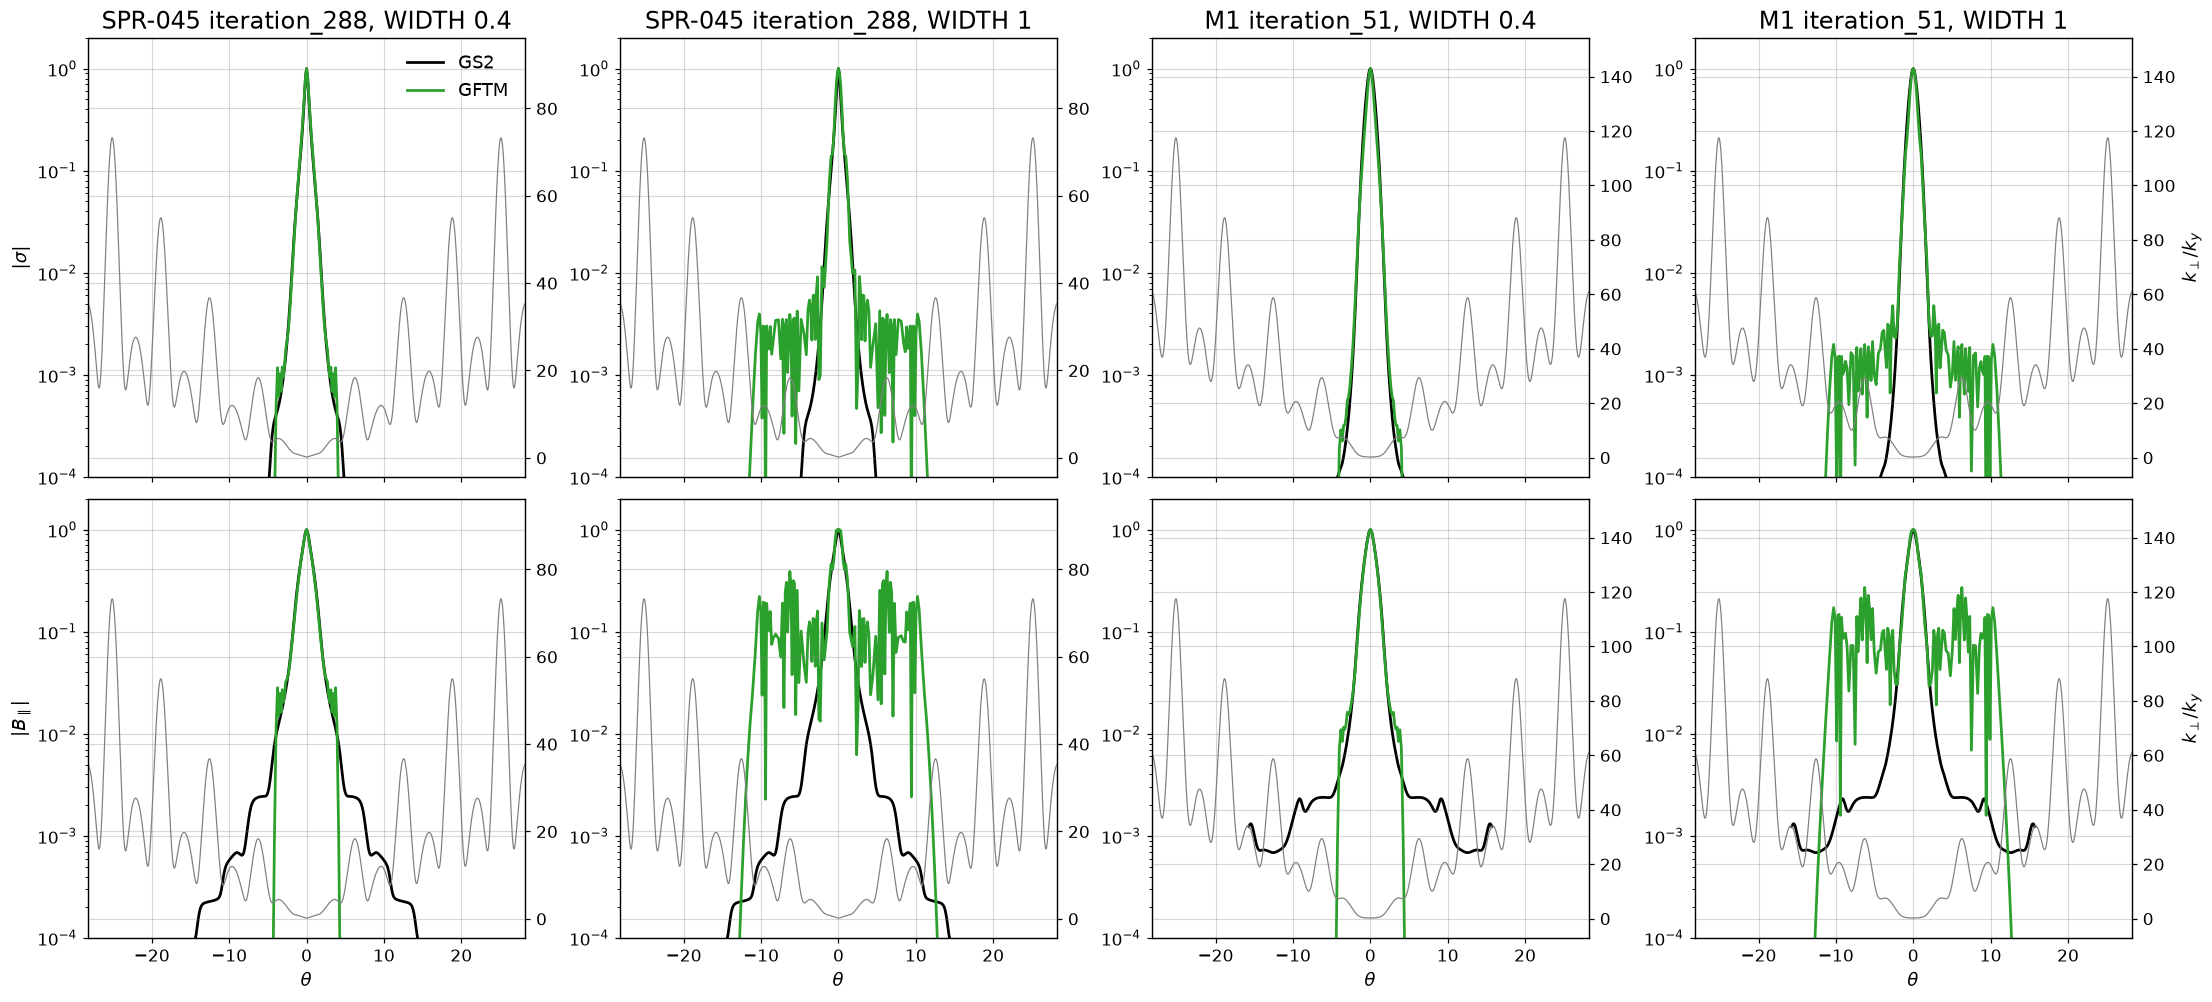

In [7]:
fig3, axes3 = plt.subplots(2, 4, figsize=(20, 9), sharex=True)
for c, (db, width) in enumerate([(db, w) for db in cases for w in (0.4, 1.0)]):
    ref = gs2[db]
    k = np.flatnonzero(ref["kbm"])
    i = k[np.argsort(ref["ext"]["bpar"][k])[len(k) // 2]]
    leaf = f"qx_f05_{wtag(width)}_nb59_nx65"
    theta_gftm, fields_raw = gftm_dominant(db, gftm_dir(db) / leaf / "pyroscan.nc")
    _, fields_converted = gftm_dominant(db, bpar_root / db / leaf / "pyroscan.nc")
    for r, (gs2_field, gftm_field, label) in enumerate(((ref["sigma"][i], fields_raw["bpar"][i], r"$|\sigma|$"),
                                                       (ref["bpar"][i], fields_converted["bpar"][i], r"$|B_\parallel|$"))):
        ax = axes3[r, c]
        ax.plot(ref["theta"], np.abs(gs2_field) / np.abs(gs2_field).max(), color="k", marker="", label="GS2")
        ax.plot(theta_gftm, np.abs(gftm_field) / np.abs(gftm_field).max(), color="C2", marker="", label="GFTM")
        ax.set(yscale="log", ylim=(1e-4, 2), xlim=(-9 * np.pi, 9 * np.pi))
        ax_k = ax.twinx()
        ax_k.plot(theta_metric[db], ref["k_perp_curves"][i], color="grey", lw=0.8, marker="")
        ax_k.set(xlim=(-9 * np.pi, 9 * np.pi))
        if c == 3:
            ax_k.set_ylabel(r"$k_\perp/k_y$")
        if c == 0:
            ax.set_ylabel(label)
    axes3[0, c].set_title(f"{db} {ref['names'][i]}, WIDTH {width:g}", fontsize=fs_title)
    axes3[1, c].set_xlabel(r"$\theta$")
axes3[0, 0].legend(fontsize=fs_legend)
plt.show()

## Real GFTM: `FIELD_GALERKIN` F vs T (Fusion_PhD-qp5.24 leaves, NBASIS 64 / NXGRID 65, same Galerkin-build binary for both arms)
Re-saved with the #613 reader (`bpar_galerkin_rebuild`, Fusion_PhD `results/gftm_bpar_extent/rebuild_galerkin_bpar.py`). The leaves hold the GS2-KBM samples of `kbm_free` only, paired to GS2 by sample name.
GS2 reference: `kbm_free/pyroscan.nc` (`eigenfunctions_squared`, which is all an extent needs; its theta is the union of the per-sample grids).

In [8]:
galerkin_root = data_root / "GFTM" / "Runs" / "bpar_galerkin_rebuild"
galerkin_cases = ["R3", "M1", "R4"]
galerkin_error = {}   # (db, arm, field) -> median |log10 extent ratio| per WIDTH
galerkin_widths = sorted(float(p.name.split("_")[1][1:].replace("p", ".")) for p in (galerkin_root / "M1").glob("galT_w*_nb64_nx65"))
for db in galerkin_cases:
    gs2_free = PyroScanGKOutput.from_netcdf(data_root / "GS2" / "Runs" / project / db / "kbm_free" / "pyroscan.nc").data
    gs2_names = list(gs2_free.sample_name.values.astype(str))
    gs2_power = gs2_free.eigenfunctions_squared.isel(kx=0).transpose("sample", "field", "theta")
    gs2_theta = mag(gs2_free.theta)
    for arm in ("galF", "galT"):
        for field in ("phi", "bpar"):
            galerkin_error[db, arm, field] = []
        for width in galerkin_widths:
            gftm_free = PyroScanGKOutput.from_netcdf(galerkin_root / db / f"{arm}_{wtag(width)}_nb64_nx65" / "pyroscan.nc").data
            names = gftm_free.sample_name.values.astype(str)
            gs2_index = np.array([gs2_names.index(n) for n in names])
            gamma = mag(gftm_free.growth_rate.transpose("sample", "mode"))
            dominant = np.argmax(np.where(gamma > 0, gamma, -np.inf), 1)
            unstable = gamma.max(1) > 0
            fields = mag(gftm_free.eigenfunctions.transpose("sample", "mode", "field", "theta"))[np.arange(len(names)), dominant]
            field_names = list(gftm_free.field.values)
            for field in ("phi", "bpar"):
                # theta is the union of the per-sample GS2 grids, so each sample is finite only on its own points
                gs2_extent = np.array([extent(gs2_theta[np.isfinite(p)], p[np.isfinite(p)]) if np.isfinite(p).sum() > 10 else np.nan
                                       for p in mag(gs2_power.sel(field=field))[gs2_index]])
                gftm_extent = np.array([extent(mag(gftm_free.theta), np.abs(e) ** 2) if ok else np.nan for e, ok in zip(fields[:, field_names.index(field)], unstable)])
                galerkin_error[db, arm, field].append(np.nanmedian(np.abs(np.log10(gftm_extent / gs2_extent))))
    print(db, "n samples", len(names), "| GS2 B_par finite:", int(np.isfinite(gs2_extent).sum()),
          "| median B_par error galF / galT at WIDTH >= 1:", round(float(np.median([e for w, e in zip(galerkin_widths, galerkin_error[db, "galF", "bpar"]) if w >= 1])), 3),
          round(float(np.median([e for w, e in zip(galerkin_widths, galerkin_error[db, "galT", "bpar"]) if w >= 1])), 3))

R3 n samples 187 | GS2 B_par finite: 187 | median B_par error galF / galT at WIDTH >= 1: 1.206 0.045


M1 n samples 140 | GS2 B_par finite: 140 | median B_par error galF / galT at WIDTH >= 1: 1.201 0.026


R4 n samples 208 | GS2 B_par finite: 208 | median B_par error galF / galT at WIDTH >= 1: 1.227 0.088


### fig4: B_par and phi extent error vs WIDTH, `FIELD_GALERKIN` F (solid) vs T (dashed)

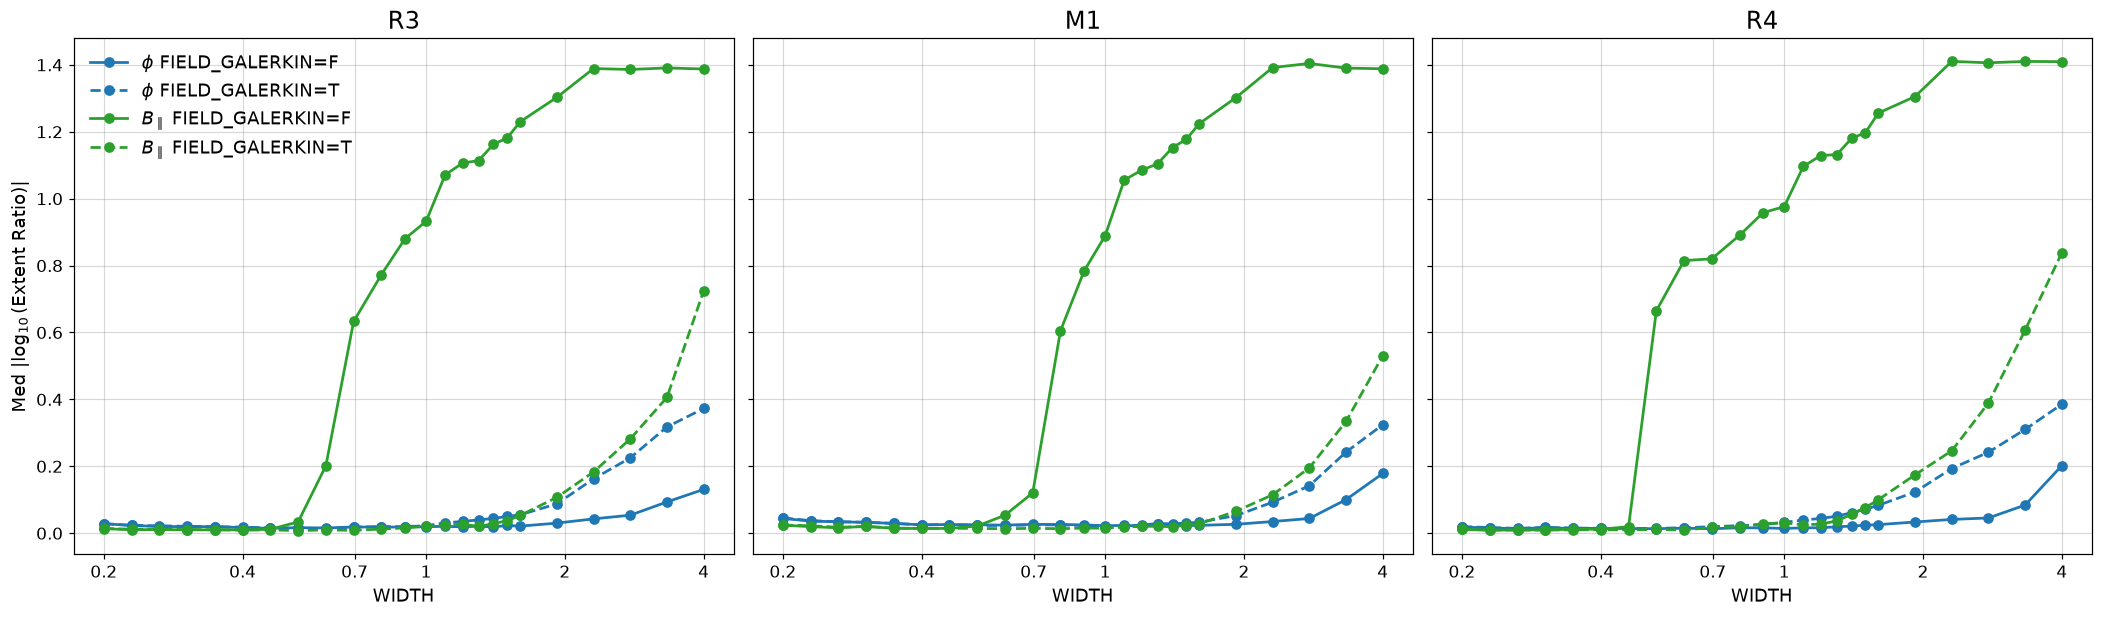

In [9]:
fig4, axes4 = plt.subplots(1, len(galerkin_cases), figsize=(19, 5.5), sharey=True)
for ax, db in zip(axes4, galerkin_cases):
    for field, colour in (("phi", "C0"), ("bpar", "C2")):
        for arm, ls in (("galF", "-"), ("galT", "--")):
            ax.plot(galerkin_widths, galerkin_error[db, arm, field], color=colour, ls=ls, label=f"{field_labels[field]} FIELD_GALERKIN={arm[-1]}")
    ax.set(xscale="log", xlabel="WIDTH")
    log_xticks(ax)
    ax.set_title(db, fontsize=fs_title)
axes4[0].set_ylabel(r"Med $|\log_{10}$(Extent Ratio)$|$")
axes4[0].legend(fontsize=fs_legend)
plt.show()

In [10]:
out = ROOT / "Plots" / analysis_name
out.mkdir(parents=True, exist_ok=True)
for name, fig in (("fig1_bpar_extent_vs_width", fig1), ("fig2_synthetic_vs_nbasis", fig2), ("fig3_eigenfunctions", fig3), ("fig4_field_galerkin", fig4)):
    fig.savefig(out / f"{name}.png", bbox_inches="tight")
print(sorted(p.name for p in out.iterdir()))

['fig1_bpar_extent_vs_width.png', 'fig2_synthetic_vs_nbasis.png', 'fig3_eigenfunctions.png', 'fig4_field_galerkin.png']
